# 02 · Error analysis and shortcut search (v1)

This notebook looks for the reasons **v1** gets things right or wrong, and especially for
*shortcuts*: patterns that separate the classes in this dataset but have nothing to do with
how a human or a machine writes.

It only reads files produced by:

```powershell
python -m human_or_ai.diagnose --version v1
```

So it runs in a few seconds and never retrains anything. The written conclusions are in
[`reports/diagnosis.md`](../reports/diagnosis.md).

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from human_or_ai.shortcuts import standardize
from human_or_ai.utils import PROJECT_ROOT

DIAG = PROJECT_ROOT / "reports" / "diagnosis" / "v1"
FIG = PROJECT_ROOT / "reports" / "figures"
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.precision", 3)


def load(name):
    data = json.loads((DIAG / f"{name}.json").read_text(encoding="utf-8"))
    return pd.DataFrame(data) if isinstance(data, list) else data

## 1. Where do the tokens `nt`, `s`, `re` come from?

The v1 standardization lowercases the text and deletes punctuation, then splits on spaces.
In the human answers of the *recent* dataset (from HC3/Reddit), contractions were tokenized
with a space: `do n't`, `it 's`. The two forms become different tokens:

In [2]:
for text in ["I do n't think it 's true", "I don't think it's true", "Earth 's orbit", "Earth's orbit"]:
    print(f"{text!r:32} -> {standardize(text).split()}")

"I do n't think it 's true"      -> ['i', 'do', 'nt', 'think', 'it', 's', 'true']
"I don't think it's true"        -> ['i', 'dont', 'think', 'its', 'true']
"Earth 's orbit"                 -> ['earth', 's', 'orbit']
"Earth's orbit"                  -> ['earths', 'orbit']


The split form creates the standalone tokens `nt` and `s`; the normal form creates
`dont` and `earths`. So **the same words, written normally, land on different tokens**.

## 2. Surface patterns per class (training set)

For each pattern: share of texts that contain it, mean count per text, and the ROC-AUC of
that single count used as a classifier (0.5 = no signal, 1.0 = perfect separation).

In [3]:
shortcuts = load("shortcuts_by_class").set_index("pattern")
shortcuts[["human % texts", "ai % texts", "human mean/text", "ai mean/text", "auc_alone", "points_to"]]

,human % texts,ai % texts,human mean/text,ai mean/text,auc_alone,points_to
pattern,,,,,,
split n't (do n't),21.030,0.004,0.389,4.472e-05,0.605,human
split 's (it 's),23.902,0.018,0.514,1.789e-04,0.619,human
split 're/'ll/'ve/'m/'d,15.304,0.000,0.291,0.000e+00,0.577,human
"joined contraction (don't, it's)",5.181,37.265,0.149,8.959e-01,0.660,ai
URL_ placeholder,7.005,0.054,0.106,8.050e-04,0.535,human
real URL (http),0.975,0.049,0.011,8.050e-04,0.505,human
literal \n (backslash + n),0.000,7.263,0.000,4.722e-01,0.536,ai
real line break,0.688,58.410,0.048,2.072e+00,0.789,ai
"space before , . ; : ! ? )",56.305,3.421,7.217,4.973e-02,0.773,human


**Reading the table.**

- Split contractions (`do n't`, `it 's`, `you 're`) and the `URL_0` placeholder appear in
  15-24% and 7% of human texts, and almost never in AI texts: pure formatting artifacts.
- A **space before punctuation** (`word ,`) is in 56% of human texts and 3% of AI texts.
  On its own it separates the classes with an AUC of 0.77.
- **Real line breaks** are in 58% of AI texts and 0.7% of human texts (AUC 0.79): the human
  sources were flattened to one line, the AI answers kept their paragraphs. v1 cannot see
  line breaks (it splits on whitespace), but a future "number of paragraphs" style feature
  would learn this artifact. It must be neutralized before phase 3 (v4).
- A **literal `\n`** (backslash + n, an escaping bug in the source) appears only in AI texts.
- **Normal contractions** (`don't`, `it's`) are in 37% of AI texts and 5% of human texts.
  So a person who writes `don't` normally looks *more like the AI class*.

Same table split by source:

In [4]:
by_source = load("shortcuts_by_source").set_index("pattern")
keep = ["split n't (do n't)", "split 's (it 's)", "URL_ placeholder", "joined contraction (don't, it's)",
        "literal \\n (backslash + n)", "real line break", "space before , . ; : ! ? )"]
by_source.loc[keep, [c for c in by_source.columns if c.endswith("% texts")]]

,abstracts/human % texts,abstracts/ai % texts,recent/human % texts,recent/ai % texts
pattern,,,,
split n't (do n't),0.000,0.000,33.417,0.008
split 's (it 's),0.000,0.022,37.980,0.015
URL_ placeholder,0.000,0.000,11.130,0.091
"joined contraction (don't, it's)",3.044,10.791,6.439,55.684
literal \n (backslash + n),0.000,0.000,0.000,12.317
real line break,0.000,100.000,1.092,29.473
"space before , . ; : ! ? )",1.844,7.914,88.381,0.296


**Each dataset has its own artifacts.**

- **Recent**: 88% of human texts have a space before punctuation, against 0.3% of AI texts.
  Split contractions (33-38%) and `URL_0` (11%) appear only in human texts. The literal
  `\n` appears in 12% of AI texts and never in human ones.
- **Abstracts**: **100% of AI abstracts contain a real line break, against 0% of human
  abstracts** (the AI abstracts start with blank lines). A single "does the text contain a
  line break?" rule would separate this dataset almost perfectly.

None of these patterns says anything about how a person or a model writes.

## 3. The 30 most human and 30 most AI words

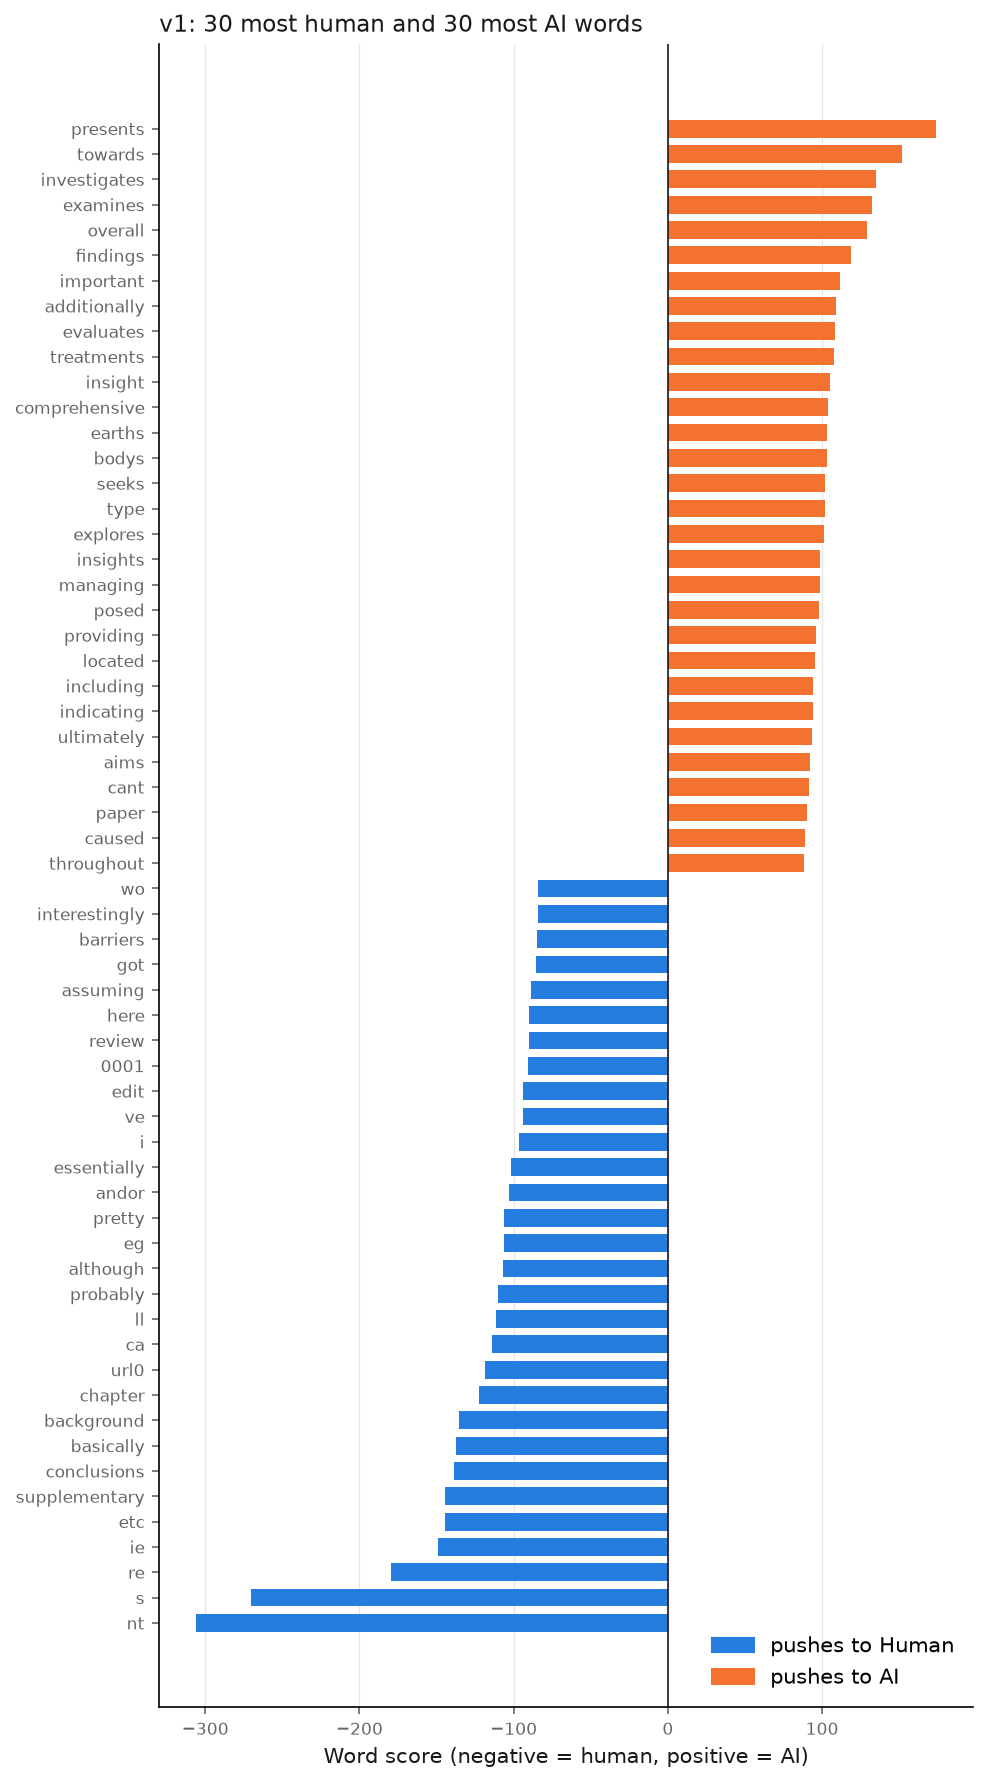

,side,word,score,human % texts,ai % texts
0,human,nt,-305.882,21.763,0.009
1,human,s,-270.078,25.107,0.385
2,human,re,-179.563,8.364,0.027
3,human,ie,-149.106,2.556,0.242
4,human,etc,-144.773,4.586,1.060
5,human,supplementary,-144.765,2.220,0.054
6,human,conclusions,-138.389,5.557,1.114
7,human,basically,-137.317,3.846,0.107
8,human,background,-135.236,6.997,0.854
9,human,chapter,-122.413,1.011,0.089


In [5]:
display(Image(FIG / "v1_top_words.png", width=520))
top = load("top_words")
top[["side", "word", "score", "human % texts", "ai % texts"]]

**Comments.**

- **Human side, artifacts**: `nt`, `s`, `re`, `ll`, `ve`, `ca` (`ca n't`), `wo` (`wo n't`)
  come from split contractions; `url0` is the URL placeholder; `ie`, `eg`, `etc`, `andor`
  are `i.e.`, `e.g.`, `and/or` once punctuation is removed.
- **Human side, format of the source**: `background`, `conclusions`, `supplementary`,
  `0001` (as in `p < 0.0001`) come from the section headers and statistics of real
  structured abstracts; `edit` is the Reddit "EDIT:" habit.
- **Human side, plausible style**: `i`, `basically`, `pretty`, `probably`, `got`, `here`.
  These are informal, first-person words: a real difference in register, though partly a
  difference between Reddit and the abstract genre.
- **AI side, plausible style**: `presents`, `investigates`, `examines`, `explores`, `aims`,
  `seeks`, `paper` ("This paper presents"), `overall`, `additionally`, `comprehensive`,
  `insights`, `ultimately`, `important`. These are the formulas expected from language models.
- **AI side, artifacts**: `earths`, `bodys`, `cant` come from the *joined* forms `Earth's`,
  `body's`, `can't`. The model learned that correct, joined spelling points to AI.

## 4. Length

In [6]:
display(load("by_length"))
display(pd.DataFrame(load("length_only_baseline")).T)
load("word_count_stats")

,group,n,n_human,n_ai,accuracy,fpr_human,tpr_ai,roc_auc,ece
0,<50,861,806,55,0.877,0.125,0.909,0.954,0.119
1,50-150,3367,1606,1761,0.958,0.060,0.974,0.994,0.013
2,150-300,4779,2348,2431,0.974,0.033,0.981,0.996,0.018
3,>300,751,586,165,0.975,0.019,0.952,0.994,0.021


,n,accuracy,roc_auc,fpr_human,tpr_ai,roc_auc_folded
all,9758.0,0.501,0.511,0.513,0.518,0.511
recent,4031.0,0.694,0.742,0.247,0.600,0.742
abstracts,5727.0,0.364,0.301,0.744,0.473,0.699


,source,label,count,mean,50%,min,max
0,abstracts,0,12026.0,213.453,205.0,3.0,18000.0
1,abstracts,1,12040.0,169.778,154.0,30.0,928.0
2,recent,0,18046.0,134.382,83.0,1.0,2038.0
3,recent,1,14731.0,173.839,174.0,1.0,544.0


**Comments.**

- Texts under 50 words are 94% human in the test set (806 of 861). On them, the false
  positive rate doubles (12.5% vs 6.0% at 50-150 words) and calibration breaks (ECE 0.12).
- Length alone is a strong clue *inside each dataset*, in opposite directions: in **recent**,
  AI answers are longer (AUC 0.74); in **abstracts**, AI abstracts are shorter (folded AUC
  0.70). Mixed together, the two effects cancel (AUC 0.51). A model can still exploit length
  once it knows which dataset a text looks like.

## 5. The most confident mistakes

In [7]:
cols = ["source", "p_ai", "words", "text"]
print("Human texts the model is most sure are AI:")
display(load("worst_false_positives")[cols])
print("AI texts the model is most sure are human:")
display(load("worst_false_negatives")[cols])

Human texts the model is most sure are AI:


,source,p_ai,words,text
0,abstracts,1.0,3,See related letter
1,recent,1.0,14,Is this a feeling that runs between your belly button and your crotch ?
2,recent,1.0,13,Because training techniques and regimens have improved between different generations of sprinters .
3,recent,1.0,49,"Its duties have expanded over the years, and today, according to official Federal Reserve documentation, include conducting the nation's monetary policy , s..."
4,recent,1.0,10,"Can you clarify the phrase "" clear up "" ?"
5,recent,1.0,32,"Theory of Mind is the ability to understand that other individuals have their own thoughts , feelings , and beliefs that are separate from your thoughts , f..."
6,recent,1.0,10,Their guide dog helps them or they use sonar .
7,recent,1.0,12,Come to northern Canada during black fly season . Its fucking hell
8,abstracts,1.0,6,How safe are our microbiology labs?
9,abstracts,1.0,7,Masao Matsuoka wins the 2011 Retrovirology Prize.


AI texts the model is most sure are human:


,source,p_ai,words,text
0,recent,0.002,272,"An EIN, or Employer Identification Number, is a unique nine-digit identification number assigned to businesses by the Internal Revenue Service (IRS) for tax..."
1,recent,0.003,155,"The average, or mean, of a set of values is a way to describe the central tendency of those values. It is found by adding up all of the values in the set an..."
2,abstracts,0.005,423,"\n\nThis paper investigates the protective effects of cinnamaldehyde (CA), a major bioactive constituent of cinnamon, on inflammation, oxidative stress and ..."
3,recent,0.007,180,Immanuel Kant's Categorical Imperative is a moral principle that says that we should always act in a way that we can will to be a universal law. In other wo...
4,recent,0.011,254,The Bellman equation is a mathematical equation that is used to describe the dynamic programming solution to a particular optimization problem. It is named ...
5,abstracts,0.017,183,\n\nThis study examines the molecular and cellular effects of chemical chaperone TUDCA on ER-stressed NHAC-kn human articular chondrocytes cultured under no...
6,abstracts,0.025,117,\n\nThis paper presents a study investigating the immunogenicity of S protein from the transmissible gastroenteritis virus (TGEV) when expressed in baculovi...
7,abstracts,0.029,231,"\n\nThe history of Streptococcus pneumoniae in Arkhangelsk, northern European Russia since the introduction of conjugate pneumococcal vaccines is important ..."
8,abstracts,0.032,43,\n\nSecure communication networks have recently come under scrutiny for their lack of security. This article examines the evolving methods used to expose hi...
9,recent,0.039,87,All human fetuses start out as female in terms of their sexual development. Both males and females have nipples because they develop before it is determined...


The worst false positives are mostly **very short** human texts (3 to 14 words) scored at
P(AI) = 1.00, plus formal, definition-like sentences. The worst false negatives are fluent
explanatory AI answers (encyclopedic style) and abstracts. The model gives them
P(AI) < 0.02: it is confidently wrong, not hesitant.

## 6. Calibration on the test set

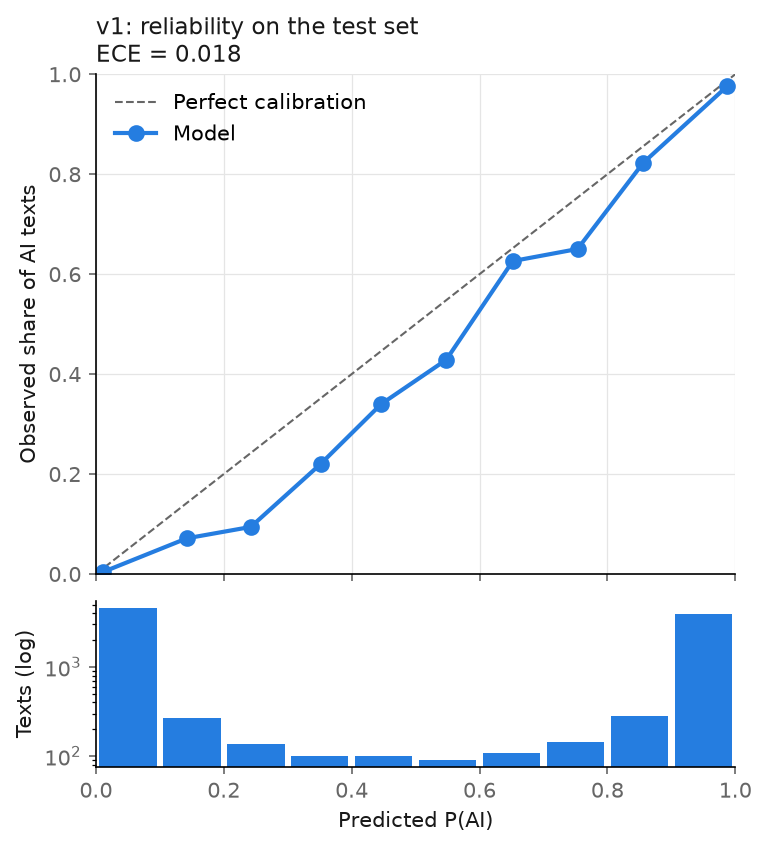

{'accuracy': 0.9599,
 'roc_auc': 0.99,
 'ece': 0.0181,
 'brier': 0.0314,
 'mean_confidence_when_wrong': 0.7675,
 'share_errors_above_90pct_conf': 0.2839}

In [8]:
m = load("test_metrics")
display(Image(FIG / "v1_reliability_test.png", width=420))
{k: round(m[k], 4) for k in ["accuracy", "roc_auc", "ece", "brier", "mean_confidence_when_wrong",
                             "share_errors_above_90pct_conf"]}

On data like its training data, v1 is well calibrated overall (ECE 0.018), because almost
all predictions sit near 0 or 1 and are right. But **28% of its errors are made with more
than 90% confidence**, and in the middle range the curve lies below the diagonal: when v1
says "60% AI", the real share of AI texts is lower.

## 7. Cross-dataset generalization

In [9]:
cross = load("cross_dataset")
cross[["train_on", "test_on", "kind", "n", "accuracy", "fpr_human", "tpr_ai", "roc_auc", "ece"]]

,train_on,test_on,kind,n,accuracy,fpr_human,tpr_ai,roc_auc,ece
0,recent,recent,in-domain,4031,0.951,0.060,0.968,0.985,0.024
1,recent,abstracts,cross,5727,0.539,0.104,0.183,0.648,0.341
2,abstracts,abstracts,in-domain,5727,0.995,0.007,0.996,0.999,0.006
3,abstracts,recent,cross,4031,0.597,0.037,0.008,0.468,0.389


This is the most important result of the diagnosis. The same architecture, trained on one
dataset, is **near chance on the other one**:

- trained on *recent*, tested on *abstracts*: accuracy 54%, AUC 0.65, and it catches only
  18% of AI abstracts;
- trained on *abstracts*, tested on *recent*: accuracy 60% (it calls almost everything
  human), AUC 0.47, and it catches 0.8% of AI answers.

The 96% test accuracy measures recognition of *familiar sources*, not detection of AI
writing in general. This matches the RAID benchmark findings (Dugan et al., ACL 2024).

## 8. Title leakage in the abstracts dataset

In [10]:
load("title_leakage")

{'val': {'abstracts': 4581,
  'title_also_in_train': 3738,
  'share': 0.8159790438768828},
 'test': {'abstracts': 5727, 'title_also_in_train': 0, 'share': 0.0},
 'train_titles_with_both_labels': 7297,
 'train_unique_titles': 11042}

The validation split was cut at random from the abstracts train split, while most titles
exist in two versions (human and AI). **82% of the abstracts used for validation share
their title with a training abstract.** The official test split does not (0%). So the test
score is not inflated by this leak, but early stopping was driven by a partly leaked
validation set. Phase 2 will split by title and compare before/after.